# 07 - Comparison methods (milestone 8)

`PROJECT_PLAN.md` §11: ICA + ICLabel (the comparison method, §11.1) and the
optional automatic-marking MWF (RELAX-style). Settings in
`configs/baselines.yaml`, fixed before any test data are touched.

mne-icalabel 0.10.0 (verified): ICLabel expects a common-average copy
band-passed 1-100 Hz and extended infomax (here picard, `ortho=False,
extended=True`). Section A runs at 128 Hz, so the copy is 1-63 Hz - a stated
limitation of the baseline. ICLabel is a neural network; it is allowed
because this is the baseline, never part of the proposed method.

The comparison below uses a Set A noise subject and **oracle** flags for the
proposed methods (the detector comes in at milestone 9); both baselines mark
artifacts themselves.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adr.config import load_paths, package_versions, seed_everything

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
pd.set_option("display.max_columns", 50, "display.width", 200)
paths = load_paths()
seed_everything()
package_versions()

{'python': '3.14.8',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'pandas': '3.0.6',
 'mne': '1.13.2',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.2',
 'eelbrain': '0.43.0b0',
 'matplotlib': '3.11.2',
 'mne-icalabel': '0.10.0'}

In [2]:
from adr.baselines import ica_iclabel, mwf_auto
from adr.reconstruction import check
from adr.synth import dataset3 as d3, inject as I, templates as T

RUN_CHECK = False   # True: recompute (ICA takes ~40 s per recording; ~6 min total)
table = (pd.concat([check.run(sar_db=s, baselines=True) for s in (0, -10)]) if RUN_CHECK
         else pd.read_csv(paths["results"] / "section_a" / "reconstruction_check.csv"))
order = ["no correction", "routed (oracle flags)", "single MWF (oracle flags)", "ICA+ICLabel (p>=0.7)",
         "ICA+ICLabel (p>=0.5)", "ICA+ICLabel (p>=0.9)", "auto-MWF (RELAX-style)"]
table.pivot_table(index=["sar_db", "type"], columns="pipeline", values="rrmse_analysis_flagged_excl_native")[order].round(3)

pipeline       no correction  routed (oracle flags)  single MWF (oracle flags)  ICA+ICLabel (p>=0.7)  ICA+ICLabel (p>=0.5)  ICA+ICLabel (p>=0.9)  auto-MWF (RELAX-style)
sar_db type                                                                                                                                                             
-10    motion          4.912                  0.582                      0.582                 4.910                 4.910                 4.923                   0.655
       muscle          2.018                  0.581                      0.571                 2.009                 2.018                 2.007                   0.732
       ocular          5.245                  0.753                      0.687                 2.510                 2.506                 2.502                   0.648
       pop             0.290                  0.151                      0.332                 0.657                 0.660                 0.660                   0.664
 0     motion          1.553                  0.540                      0.540                 1.640                 1.641                 1.638                   0.728
       muscle          0.638                  0.529                      0.518                 0.853                 0.879                 0.855                   0.729
       ocular          1.659                  0.716                      0.668                 0.973                 0.999                 0.938                   0.627
       pop             0.092                  0.147                      0.173                 0.626                 0.633                 0.624                   0.568

Error over the **whole** recording (1-9 Hz, native transients excluded):
both baselines change clean data too (ICA removes components everywhere;
RELAX applies its MWFs to the whole recording), while the proposed methods
only touch flagged samples.

In [3]:
table.pivot_table(index=["sar_db", "type"], columns="pipeline", values="rrmse_analysis_all_excl_native")[order].round(3)

pipeline       no correction  routed (oracle flags)  single MWF (oracle flags)  ICA+ICLabel (p>=0.7)  ICA+ICLabel (p>=0.5)  ICA+ICLabel (p>=0.9)  auto-MWF (RELAX-style)
sar_db type                                                                                                                                                             
-10    motion          2.666                  0.316                      0.316                 2.700                 2.700                 2.704                   0.614
       muscle          0.860                  0.249                      0.244                 1.020                 1.040                 0.979                   0.723
       ocular          2.314                  0.334                      0.304                 1.210                 1.217                 1.194                   0.592
       pop             0.118                  0.062                      0.135                 0.636                 0.646                 0.635                   0.579
 0     motion          0.843                  0.293                      0.293                 1.032                 1.034                 1.028                   0.632
       muscle          0.272                  0.226                      0.222                 0.650                 0.686                 0.643                   0.639
       ocular          0.732                  0.318                      0.295                 0.652                 0.689                 0.596                   0.545
       pop             0.037                  0.060                      0.071                 0.625                 0.633                 0.623                   0.561

## What the baselines remove / mark

In [4]:
display(table[table["pipeline"] == "ICA+ICLabel (p>=0.7)"][["sar_db", "type", "removed"]])
table[table["pipeline"] == "auto-MWF (RELAX-style)"][["sar_db", "type", "marked"]]

,sar_db,type,removed
3,0,ocular,"{'eye blink': 3, 'muscle artifact': 11, 'chann..."
10,0,muscle,"{'eye blink': 2, 'muscle artifact': 11, 'chann..."
17,0,motion,"{'eye blink': 3, 'muscle artifact': 11, 'chann..."
24,0,pop,"{'eye blink': 2, 'muscle artifact': 12, 'chann..."
31,-10,ocular,"{'eye blink': 6, 'muscle artifact': 7, 'channe..."
38,-10,muscle,"{'heart beat': 1, 'muscle artifact': 11, 'eye ..."
45,-10,motion,"{'eye blink': 5, 'muscle artifact': 10, 'chann..."
52,-10,pop,"{'eye blink': 2, 'muscle artifact': 13, 'chann..."


,sar_db,type,marked
6,0,ocular,"muscle 0.04, blink 0.02"
13,0,muscle,"muscle 0.15, blink 0.01"
20,0,motion,"muscle 0.04, blink 0.01"
27,0,pop,"muscle 0.04, blink 0.01"
34,-10,ocular,"muscle 0.04, blink 0.12"
41,-10,muscle,"muscle 0.18, blink 0.01"
48,-10,motion,"muscle 0.04, blink 0.01"
55,-10,pop,"muscle 0.04, blink 0.01"


## ICLabel on one recording

Top class and probability of every component for an ocular recording
(SAR -10 dB). At 128 Hz many background components come out as "muscle
artifact" or "channel noise".

label
brain              23
other              14
eye blink          12
muscle artifact    10
channel noise       4
Name: count, dtype: int64

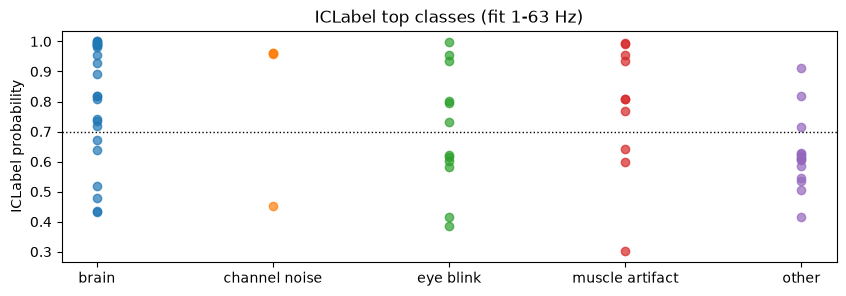

In [5]:
base, lags, _ = d3.load_base_trfs()
rec = d3.synthesize(d3.noise_source(d3.load_noise_split()["set_a"][0]), "L", -10, base, lags)
names = list(rec.ch_names)
inj = I.inject(rec.eeg, 128.0, "ocular", -10, np.random.default_rng(0), bank=T.load_bank("phantom_set_a_templates"), ch_names=names)
ica, labels, probs, band = ica_iclabel.fit_and_label(inj.eeg, 128.0, names)
comp = pd.DataFrame({"label": labels, "p": probs}).sort_values(["label", "p"], ascending=[True, False])
fig, ax = plt.subplots(figsize=(10, 3))
for lab, grp in comp.groupby("label"):
    ax.scatter([lab] * len(grp), grp["p"], alpha=0.7)
ax.axhline(0.7, color="k", ls=":", lw=1); ax.set_ylabel("ICLabel probability"); ax.set_title(f"ICLabel top classes (fit {band[0]:.0f}-{band[1]:.0f} Hz)")
comp["label"].value_counts()

## RELAX-style muscle threshold: calibrated on Set A

The RELAX default (log-log PSD slope over 7-60 Hz > -0.59) marked 46-90 % of
artifact-free Section A windows at 128 Hz. Open item 14 (decided): the
threshold was calibrated on Set A to mark 5 % of artifact-free windows and
frozen in `configs/baselines.yaml` (`scripts/13_calibrate_relax.py`).

frozen threshold: 0.777


,quantile_per_subject,marked_at_threshold,marked_at_relax_default
S4,0.588,0.025,0.688
S5,1.026,0.100,0.822
S6,1.021,0.100,0.903
S7,0.291,0.005,0.504
S8,0.262,0.003,0.526
S10,0.966,0.081,0.843
S11,1.196,0.130,0.783
S14,0.336,0.010,0.460


sensitivity  false_mark_rate
sar_db threshold                                  
-10    RELAX default        0.965            0.689
       calibrated           0.766            0.056
 0     RELAX default        0.941            0.689
       calibrated           0.597            0.056

Text(0.5, 1.0, 'Artifact-free Set A recording')

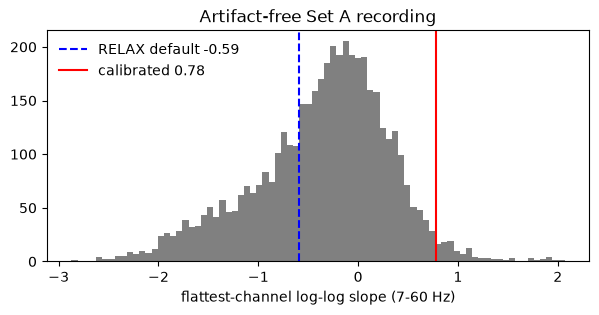

In [6]:
import json
from adr.config import load_yaml
cal = json.load(open(paths["results"] / "section_a" / "relax_muscle_calibration.json"))
print("frozen threshold:", load_yaml("baselines")["mwf_auto"]["muscle_slope_threshold"])
display(pd.DataFrame({k: cal[k] for k in ("quantile_per_subject", "marked_at_threshold", "marked_at_relax_default")}).round(3))
check_tab = pd.read_csv(paths["results"] / "section_a" / "relax_muscle_calibration_check.csv")
display(check_tab.groupby(["sar_db", "threshold"])[["sensitivity", "false_mark_rate"]].mean().round(3))
slopes = mwf_auto.muscle_slopes(rec.eeg, 128.0)
plt.figure(figsize=(7, 3))
plt.hist(slopes, bins=80, color="0.5")
plt.axvline(-0.59, color="b", ls="--", label="RELAX default -0.59")
plt.axvline(cal["threshold"], color="r", label=f"calibrated {cal['threshold']:.2f}")
plt.xlabel("flattest-channel log-log slope (7-60 Hz)"); plt.legend(frameon=False); plt.title("Artifact-free Set A recording")